In [ ]:
'''Integrate live real-time data streams (Kafka, WebSockets) into Streamlit apps to enable dynamic, 
on-the-fly predictions and continuously updated analytics dashboards.'''

In [1]:
# load dataset and prepare streaming feature schema
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
import joblib

df = pd.read_csv("global_pharmacy_sales_data.csv")
print("dataset size:", df.shape)
print(df[['date', 'category', 'medicine', 'units_sold', 'unit_price', 'stock_level', 'covid_flag']].head(3))


dataset size: (177990, 14)
         date category    medicine  units_sold  unit_price  stock_level  \
0  2025-10-12  Chronic  Amlodipine         328       45.38         4774   
1  2020-09-15  Chronic  Amlodipine         371       75.49         4584   
2  2020-02-26  Vitamin   Vitamin C         948       22.51         3934   

   covid_flag  
0           0  
1           1  
2           1  


In [2]:
# train streaming random forest model and export artifacts
features = ['category', 'medicine', 'unit_price', 'stock_level', 'covid_flag']
train_df = df[features + ['units_sold']].dropna()

encoders = {}
for col in ['category', 'medicine']:
    le = LabelEncoder()
    train_df[col] = le.fit_transform(train_df[col])
    encoders[col] = le

X = train_df[features]
y = train_df['units_sold']

stream_model = RandomForestRegressor(n_estimators=40, max_depth=8, random_state=42)
stream_model.fit(X, y)

joblib.dump(stream_model, "stream_model.pkl")
joblib.dump(encoders, "stream_encoders.pkl")
joblib.dump(features, "stream_features.pkl")
print("streaming model and encoders saved successfully")


streaming model and encoders saved successfully


In [3]:
# simulate streaming event generator with anomaly and stock alerts
def simulate_live_stream(dataset, n_events=20):
    stream_buffer = []
    for i, row in dataset.iloc[:n_events].iterrows():
        cat_enc = encoders['category'].transform([row['category']])[0]
        med_enc = encoders['medicine'].transform([row['medicine']])[0]
        input_data = pd.DataFrame([{
            'category': cat_enc,
            'medicine': med_enc,
            'unit_price': float(row['unit_price']),
            'stock_level': int(row['stock_level']),
            'covid_flag': int(row['covid_flag'])
        }])
        pred = stream_model.predict(input_data)[0]
        actual = int(row['units_sold'])
        stock = int(row['stock_level'])
        is_alert = pred > stock
        stream_buffer.append({
            'event_id': i + 1,
            'timestamp': row['date'],
            'medicine': row['medicine'],
            'unit_price': float(row['unit_price']),
            'actual_units': actual,
            'predicted_units': round(float(pred), 2),
            'stock_level': stock,
            'stock_alert': is_alert
        })
    return pd.DataFrame(stream_buffer)

stream_df = simulate_live_stream(df, n_events=20)
print(stream_df[['event_id', 'medicine', 'actual_units', 'predicted_units', 'stock_level', 'stock_alert']].head(5))


   event_id    medicine  actual_units  predicted_units  stock_level  \
0         1  Amlodipine           328           286.77         4774   
1         2  Amlodipine           371           441.80         4584   
2         3   Vitamin C           948           949.04         3934   
3         4  Amlodipine           275           401.57         4544   
4         5  Amlodipine           563           577.26         4284   

   stock_alert  
0        False  
1        False  
2        False  
3        False  
4        False  


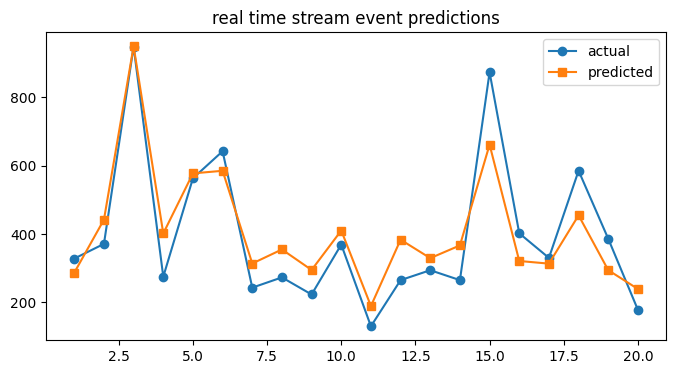

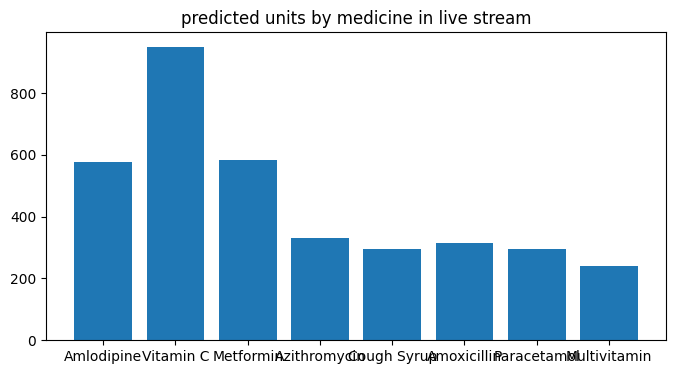

In [4]:
# plot real time streaming trends and demand distribution
plt.figure(figsize=(8, 4))
plt.plot(stream_df['event_id'], stream_df['actual_units'], label='actual', marker='o')
plt.plot(stream_df['event_id'], stream_df['predicted_units'], label='predicted', marker='s')
plt.title("real time stream event predictions")
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(stream_df['medicine'], stream_df['predicted_units'])
plt.title("predicted units by medicine in live stream")
plt.show()


In [5]:
# build full real time streaming analytics dashboard in streamlit
stream_app_code = '''import streamlit as st
import pandas as pd
import numpy as np
import time
import joblib

st.set_page_config(page_title="Live Stream Pharmacy Analytics", layout="wide")
st.title("Real-Time Pharmacy Streaming Analytics & On-The-Fly Prediction")

@st.cache_resource
def load_stream_artifacts():
    model = joblib.load("stream_model.pkl")
    encoders = joblib.load("stream_encoders.pkl")
    features = joblib.load("stream_features.pkl")
    df = pd.read_csv("global_pharmacy_sales_data.csv")
    return model, encoders, features, df

model, encoders, features, df = load_stream_artifacts()

st.sidebar.header("Stream Configuration")
stream_speed = st.sidebar.slider("Streaming Speed (seconds)", 0.2, 2.0, 0.5)
stream_events = st.sidebar.slider("Number of Stream Events", 10, 60, 25)
selected_cat = st.sidebar.selectbox("Filter Stream by Category", ["All"] + list(df['category'].unique()))
start_stream = st.sidebar.button("Launch Live Stream Pipeline")

kpi1, kpi2, kpi3, kpi4 = st.columns(4)
kpi1_box = kpi1.empty()
kpi2_box = kpi2.empty()
kpi3_box = kpi3.empty()
kpi4_box = kpi4.empty()

chart_container = st.empty()
alert_container = st.empty()
table_container = st.empty()

if start_stream:
    stream_source = df if selected_cat == "All" else df[df['category'] == selected_cat]
    stream_records = []
    
    for i in range(stream_events):
        sample_row = stream_source.sample(1).iloc[0]
        cat_code = encoders['category'].transform([sample_row['category']])[0]
        med_code = encoders['medicine'].transform([sample_row['medicine']])[0]
        
        feat_df = pd.DataFrame([{
            'category': cat_code,
            'medicine': med_code,
            'unit_price': float(sample_row['unit_price']),
            'stock_level': int(sample_row['stock_level']),
            'covid_flag': int(sample_row['covid_flag'])
        }])
        
        pred_units = model.predict(feat_df)[0]
        actual_units = int(sample_row['units_sold'])
        stock = int(sample_row['stock_level'])
        is_low_stock = pred_units > stock
        
        stream_records.append({
            'Tick': i + 1,
            'Timestamp': sample_row['date'],
            'Category': sample_row['category'],
            'Medicine': sample_row['medicine'],
            'Actual Units': actual_units,
            'Predicted Units': round(float(pred_units), 2),
            'Stock Level': stock,
            'Stock Alert': "CRITICAL" if is_low_stock else "Normal"
        })
        
        curr_stream_df = pd.DataFrame(stream_records)
        
        kpi1_box.metric("Events Ingested", len(curr_stream_df))
        kpi2_box.metric("Latest Prediction", f"{pred_units:.1f} units")
        kpi3_box.metric("Avg Predicted Demand", f"{curr_stream_df['Predicted Units'].mean():.1f}")
        critical_count = (curr_stream_df['Stock Alert'] == "CRITICAL").sum()
        kpi4_box.metric("Stock Alerts", critical_count)
        
        chart_container.line_chart(curr_stream_df.set_index('Tick')[['Actual Units', 'Predicted Units']])
        
        if is_low_stock:
            alert_container.warning(f"Stock Alert on Event #{i+1}: {sample_row['medicine']} demand ({pred_units:.1f}) exceeds stock ({stock})!")
        
        table_container.dataframe(curr_stream_df.tail(6), use_container_width=True)
        time.sleep(stream_speed)
'''

with open("app.py", "w") as f:
    f.write(stream_app_code.strip())
print("stream dashboard app.py saved successfully")


stream dashboard app.py saved successfully


In [6]:
# display instructions to start live stream dashboard
print("run 'streamlit run app.py' in terminal to launch live streaming dashboard")


run 'streamlit run app.py' in terminal to launch live streaming dashboard
